## Imports:

In [1]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno
from scipy import stats
import matplotlib.gridspec as gridspec

## set global sns:

In [2]:
sns.set_theme(style="darkgrid",palette='muted',font_scale=1.1)
COLORS = {"survived": "#2ecc71", "died": "#e74c3c", "neutral": "#3498db" }
plt.rcParams['figure.dpi'] = 110


## Phase 1: Load and first look:

In [3]:
# Paths come from a .env file (see .env.example); defaults work if you run from this folder.
import os
from pathlib import Path
from dotenv import load_dotenv, find_dotenv

load_dotenv(find_dotenv(usecwd=True))
DATA_DIR   = Path(os.getenv("DATA_DIR", "."))          # folder holding train.csv / test.csv
PLOTS_DIR  = Path(os.getenv("PLOTS_DIR", "tmp"))        # EDA plots are saved here
MODELS_DIR = Path(os.getenv("MODELS_DIR", "tmp_models"))  # saved model pickles
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

In [4]:
df = pd.read_csv(DATA_DIR / 'train.csv')
# print(df.head())
print("n data types:::::::")
print(df.dtypes)
print(f"n shape: {df.shape}....")
print("stat summary::::")
print(df.describe().T.round(2))
print("unique values per col::::")
print(df.nunique())

n data types:::::::
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object
n shape: (891, 12)....
stat summary::::
             count    mean     std   min     25%     50%    75%     max
PassengerId  891.0  446.00  257.35  1.00  223.50  446.00  668.5  891.00
Survived     891.0    0.38    0.49  0.00    0.00    0.00    1.0    1.00
Pclass       891.0    2.31    0.84  1.00    2.00    3.00    3.0    3.00
Age          714.0   29.70   14.53  0.42   20.12   28.00   38.0   80.00
SibSp        891.0    0.52    1.10  0.00    0.00    0.00    1.0    8.00
Parch        891.0    0.38    0.81  0.00    0.00    0.00    0.0    6.00
Fare         891.0   32.20   49.69  0.00    7.91   14.45   31.0  512.33
unique values per col::::
PassengerId    891
Survived         2
Pclass    

## phase 2: missing value analysis:

In [5]:
missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percentage": (df.isnull().sum() / len(df) * 100).round(2)
}).query("missing_count > 0").sort_values(by="missing_percentage", ascending=False)
print("missing values::::")
print(missing)

missing values::::
          missing_count  missing_percentage
Cabin               687               77.10
Age                 177               19.87
Embarked              2                0.22


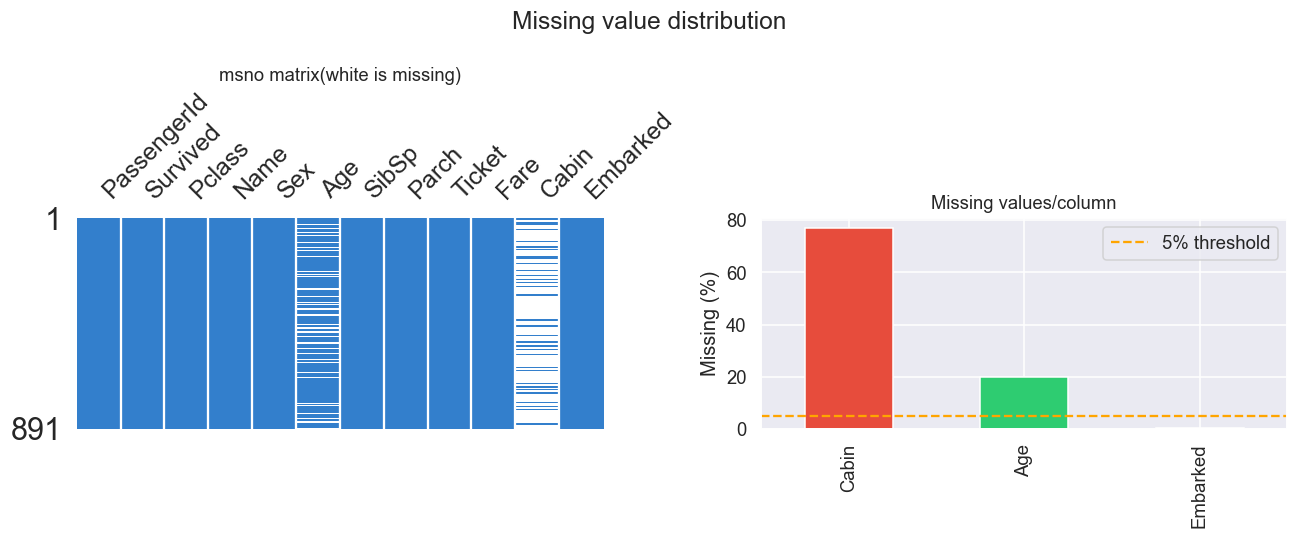

saved to tmp/phase2_missing.png


In [6]:
#visualize missing values:
fig,axes = plt.subplots(1,2,figsize=(12,5))
fig.suptitle("Missing value distribution", fontsize=16)
msno.matrix(df,ax=axes[0],sparkline=False,color=(0.2,0.5,0.8))
axes[0].set_title("msno matrix(white is missing)", fontsize=12)
missing_pct = (df.isnull().sum()/len(df)*100).sort_values(ascending=False)
missing_pct[missing_pct > 0].plot(kind='bar', ax=axes[1], color=[COLORS['died'], COLORS['survived']])
axes[1].set_title("Missing values/column", fontsize=12)
axes[1].set_ylabel("Missing (%)")
axes[1].axhline(5,color='orange', linestyle='--', label='5% threshold')
axes[1].legend()
plt.tight_layout()
plt.savefig(PLOTS_DIR / "phase2_missing.png",bbox_inches='tight')
plt.show()
print(f"saved to {PLOTS_DIR.name}/phase2_missing.png")

## phase 3: class imbalance check:

In [7]:
survival_counts = df['Survived'].value_counts()
surv_pct = df['Survived'].value_counts(normalize=True) * 100

print(f"total survived :{survival_counts[1]}, total percentage survived: {surv_pct[1]:.2f}%")
print(f"total died :{survival_counts[0]}, total percentage died: {surv_pct[0]:.2f}%")
print(f"class imbalance ratio(died/survived): {survival_counts[0]/survival_counts[1]:.2f}")


total survived :342, total percentage survived: 38.38%
total died :549, total percentage died: 61.62%
class imbalance ratio(died/survived): 1.61


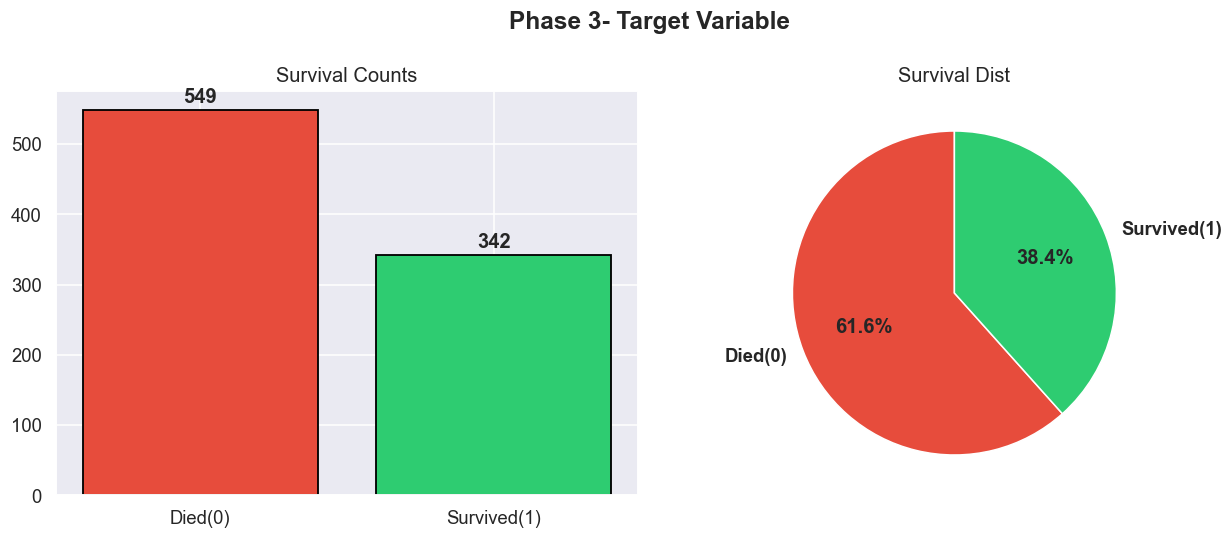

saved to tmp/phase3_target.png


In [8]:
#visualization of target variable distribution:
fig,axes = plt.subplots(1,2,figsize=(12,5))
fig.suptitle("Phase 3- Target Variable", fontsize=16,fontweight='bold')

axes[0].bar(["Died(0)","Survived(1)"], survival_counts.values, color=[COLORS['died'], COLORS['survived']],edgecolor='black',linewidth=1.2)
axes[0].set_title("Survival Counts")
for i,v in enumerate(survival_counts.values):
    axes[0].text(i, v + 10, str(v), ha='center', fontweight='bold')

axes[1].pie(survival_counts.values, labels=["Died(0)","Survived(1)"], autopct='%1.1f%%', colors=[COLORS['died'], COLORS['survived']], startangle=90, textprops={'fontweight':'bold'})
axes[1].set_title("Survival Dist")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "phase3_target.png",bbox_inches='tight')
plt.show()
print(f"saved to {PLOTS_DIR.name}/phase3_target.png")

## Phase 4: Univariate analysis:

In [9]:
num_cols = ["Age","Fare","SibSp","Parch"]
cat_cols = ["Survived","Pclass","Sex","Embarked"]

### numerical col - dist:

  Age      → skewness: +0.389  (approx normal)
  Age      → kurtosis: +0.178  (bell-shaped)
  Fare     → skewness: +4.787  (right-skewed → log transform candidate)
  Fare     → kurtosis: +33.398  (heavy-tailed)
  SibSp    → skewness: +3.695  (right-skewed → log transform candidate)
  SibSp    → kurtosis: +17.880  (heavy-tailed)


  Parch    → skewness: +2.749  (right-skewed → log transform candidate)
  Parch    → kurtosis: +9.778  (heavy-tailed)


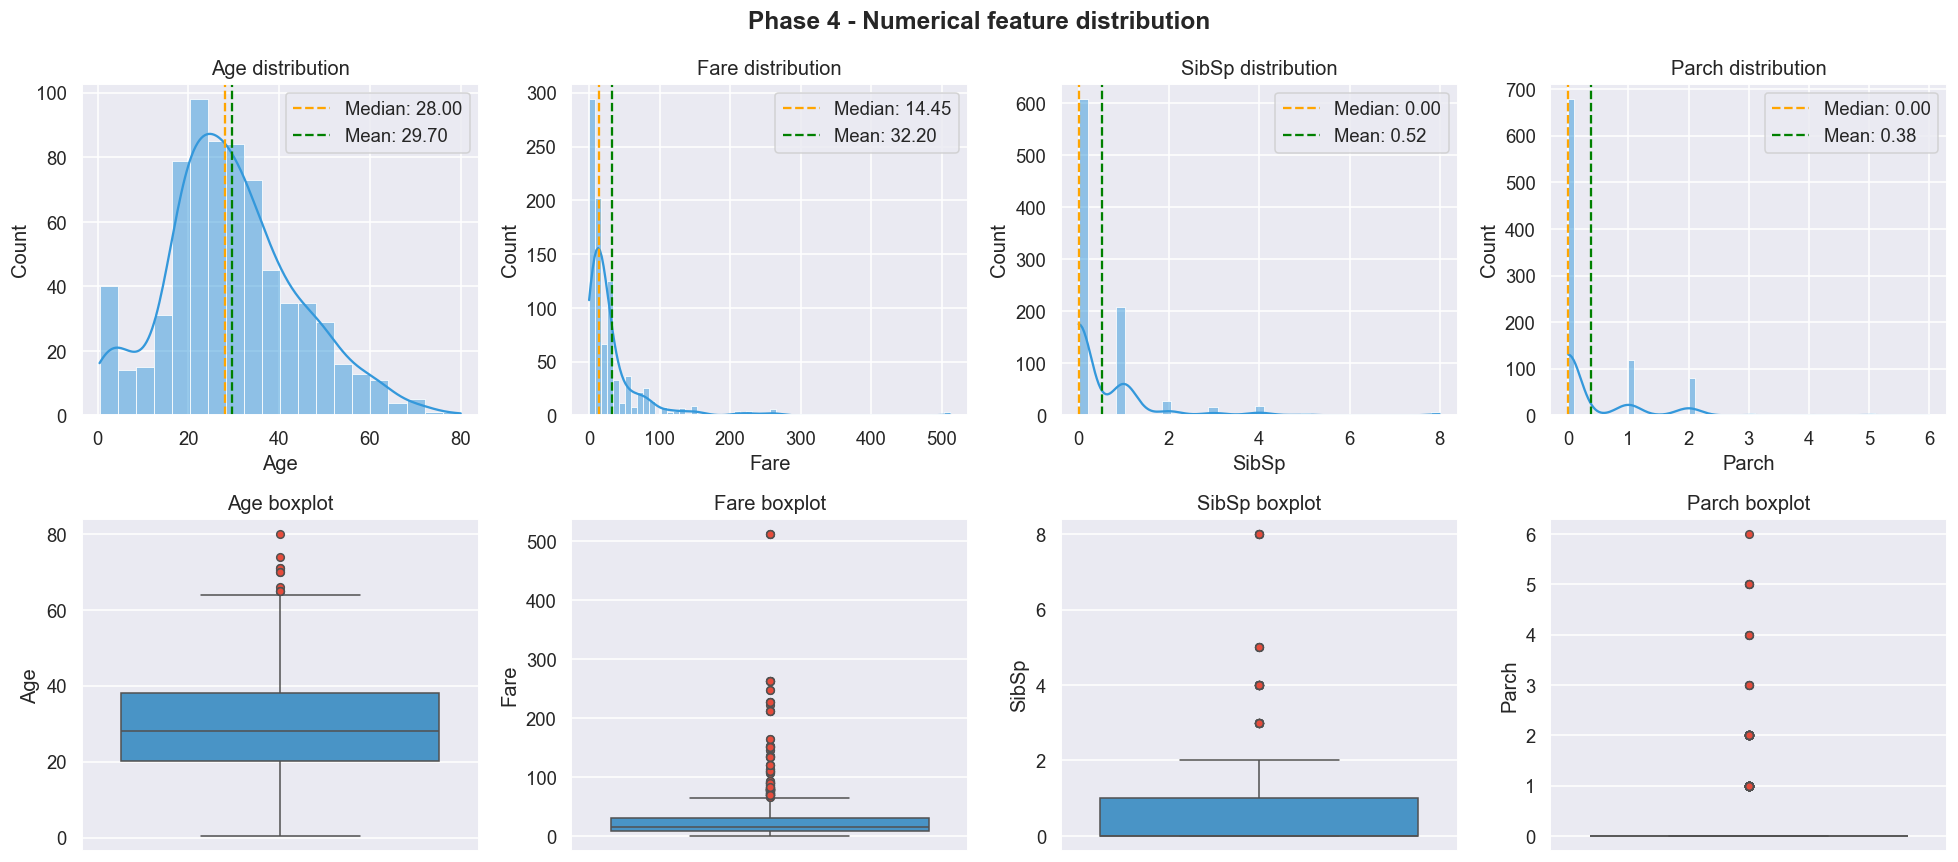

saved to tmp/phase4_numerical.png


In [10]:
#numerical distribution:
fig,axes = plt.subplots(2,4,figsize=(18,8))
fig.suptitle("Phase 4 - Numerical feature distribution", fontsize=16,fontweight='bold')

for i, col in enumerate(num_cols):
    #histogram + Kde
    ax1 = axes[0,i]
    sns.histplot(df[col],kde=True,ax=ax1,color=COLORS['neutral'],edgecolor='white',linewidth=0.5)
    ax1.axvline(df[col].median(), color='orange', linestyle='--', label=f'Median: {df[col].median():.2f}')
    ax1.axvline(df[col].mean(), color='green', linestyle='--', label=f'Mean: {df[col].mean():.2f}')
    ax1.set_title(f"{col} distribution")
    ax1.legend()

    #boxplot
    ax2 = axes[1,i]
    sns.boxplot(y=df[col].dropna(),ax=ax2,color=COLORS['neutral'],flierprops=dict(marker='o',markerfacecolor=COLORS['died'],markersize=5))
    ax2.set_title(f"{col} boxplot")

    #print skewness and kurtosis
    skew = df[col].skew()
    kurt = df[col].kurtosis()
    print(f"  {col:8s} → skewness: {skew:+.3f}  {'(right-skewed → log transform candidate)' if skew > 1 else '(left-skewed)' if skew < -1 else '(approx normal)'}")
    print(f"  {col:8s} → kurtosis: {kurt:+.3f}  {'(heavy-tailed)' if kurt > 1 else '(light-tailed)' if kurt < -1 else '(bell-shaped)'}")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "phase4_numerical.png",bbox_inches='tight')
plt.show()
print(f"saved to {PLOTS_DIR.name}/phase4_numerical.png")

### categorical dist:

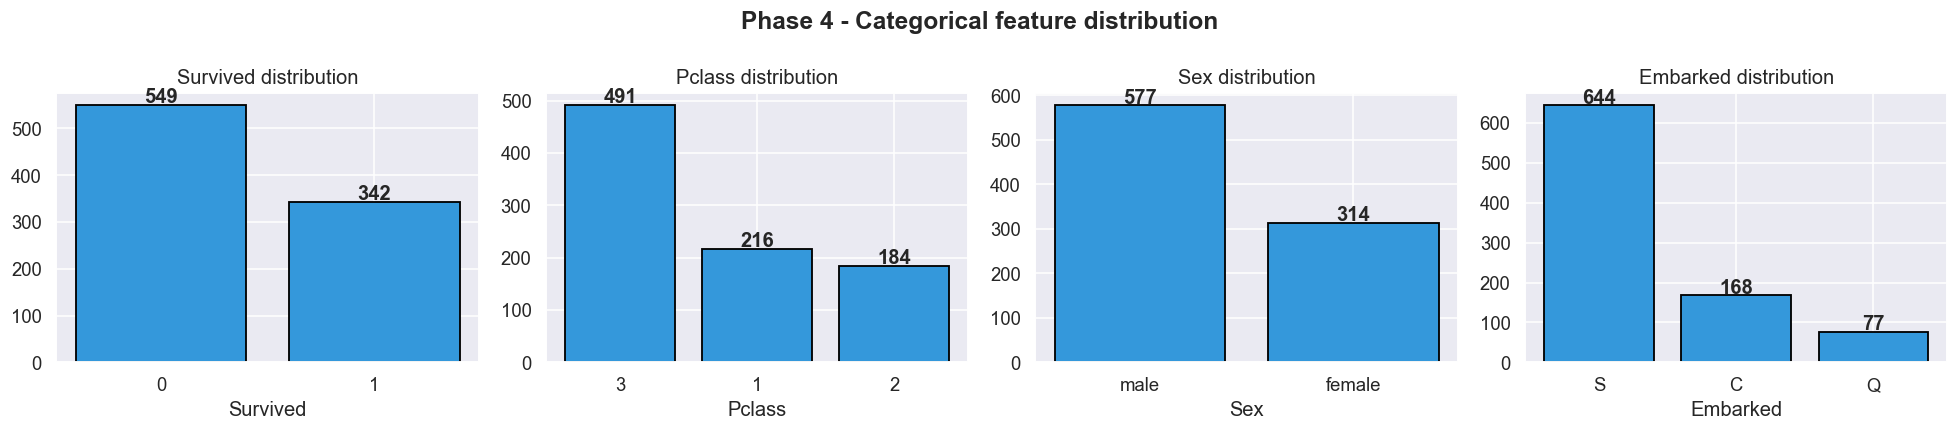

saved to tmp/phase4_categorical.png


In [11]:
fig,axes = plt.subplots(1,4,figsize=(18,4))
fig.suptitle("Phase 4 - Categorical feature distribution", fontsize=16,fontweight='bold')

for i, col in enumerate(cat_cols):
    counts = df[col].value_counts()
    axes[i].bar(counts.index.astype(str), counts.values, color=[COLORS['neutral']], edgecolor='black', linewidth=1.2)
    axes[i].set_title(f"{col} distribution")
    axes[i].set_xlabel(col)
    for j, v in enumerate(counts.values):
        axes[i].text(j, v + 5, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig(PLOTS_DIR / "phase4_categorical.png",bbox_inches='tight')
plt.show()
print(f"saved to {PLOTS_DIR.name}/phase4_categorical.png")

## Phase 5: bivariate analysis

### Categorical features vs Survival:

Survival rate by Sex:
Sex
female    74.2
male      18.9
Name: Survived, dtype: float64
Survival rate by Pclass:
Pclass
1    63.0
2    47.3
3    24.2
Name: Survived, dtype: float64
Survival rate by Embarked:
Embarked
C    55.4
Q    39.0
S    33.7
Name: Survived, dtype: float64


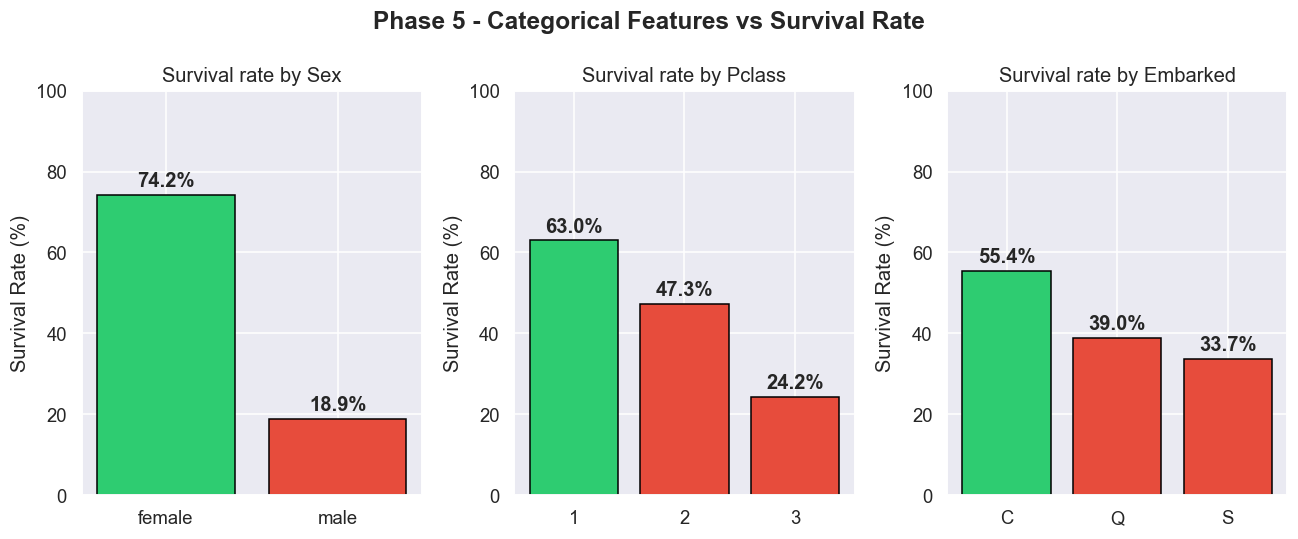

saved to tmp/phase5_bivariate_categorical_survival.png


In [12]:
fig,axes = plt.subplots(1,3,figsize=(12,5))
fig.suptitle("Phase 5 - Categorical Features vs Survival Rate", fontsize=16,fontweight='bold')

for i,col in enumerate(['Sex','Pclass','Embarked']):
    survival_rate = df.groupby(col)['Survived'].mean().sort_values(ascending=False)
    colors = [COLORS['survived'] if v>0.5 else COLORS['died'] for v in survival_rate.values]
    axes[i].bar(survival_rate.index.astype(str),survival_rate.values*100, color=colors, edgecolor='black')
    axes[i].set_title(f"Survival rate by {col}")
    axes[i].set_ylabel("Survival Rate (%)")
    axes[i].set_ylim(0,100)
    for j, v in enumerate(survival_rate.values):
        axes[i].text(j, v*100 + 2, f"{v*100:.1f}%", ha='center', fontweight='bold')
    print(f"Survival rate by {col}:\n{(survival_rate*100).round(1)}")

plt.tight_layout()
plt.savefig(PLOTS_DIR / "phase5_bivariate_categorical_survival.png",bbox_inches='tight')
plt.show()
print(f"saved to {PLOTS_DIR.name}/phase5_bivariate_categorical_survival.png")

### numerical features VS Survival:

Age      --> t-statistic: -2.067, p-value: 3.912e-02 --> significant
Fare     --> t-statistic: +7.939, p-value: 6.120e-15 --> significant
SibSp    --> t-statistic: -1.054, p-value: 2.922e-01 --> not significant
Parch    --> t-statistic: +2.442, p-value: 1.480e-02 --> significant


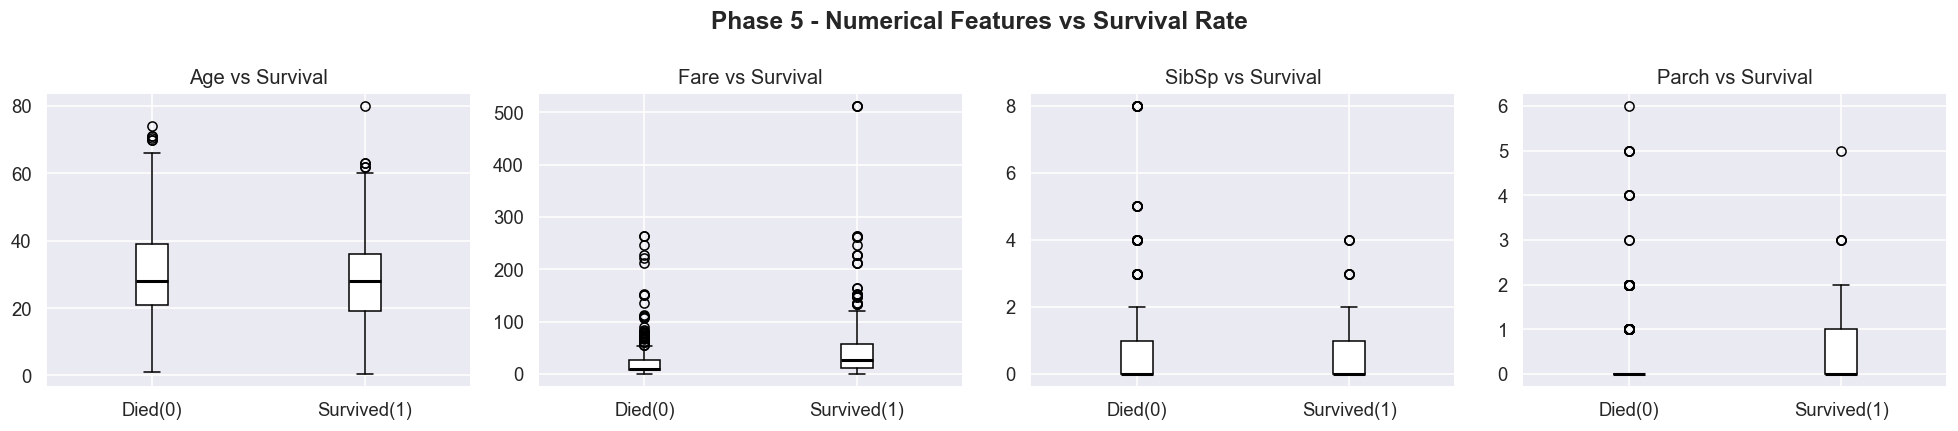

saved to tmp/phase5_bivariate_numerical_survival.png


In [13]:
fig, axes =plt.subplots(1,4,figsize=(18,4))
fig.suptitle("Phase 5 - Numerical Features vs Survival Rate", fontsize=16,fontweight='bold')

for i,col in enumerate(num_cols):

    survival_vals = df[df['Survived']==1][col].dropna()
    died_vals = df[df['Survived']==0][col].dropna()
    axes[i].boxplot([died_vals,survival_vals],labels=['Died(0)',"Survived(1)"],
    patch_artist=True,boxprops=dict(facecolor='white'),medianprops=dict(color='black',linewidth=2))
    #color individually:
    for patch, color in zip(axes[i].artists, [COLORS['died'], COLORS['survived']]):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    axes[i].set_title(f"{col} vs Survival")

    #t-test to check if difference is statistically significant:
    t,p = stats.ttest_ind(survival_vals, died_vals)
    sig = "significant" if p < 0.05 else "not significant"
    print(f"{col:8s} --> t-statistic: {t:+.3f}, p-value: {p:.3e} --> {sig}")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "phase5_bivariate_numerical_survival.png",bbox_inches='tight')
plt.show()
print(f"saved to {PLOTS_DIR.name}/phase5_bivariate_numerical_survival.png")

## Phase 6: correlation analysis:

Correlation with target variable (Survived):
Survived    1.000
Sex         0.543
Fare        0.257
Embarked    0.109
Parch       0.082
SibSp      -0.035
Age        -0.077
Pclass     -0.338
Name: Survived, dtype: float64


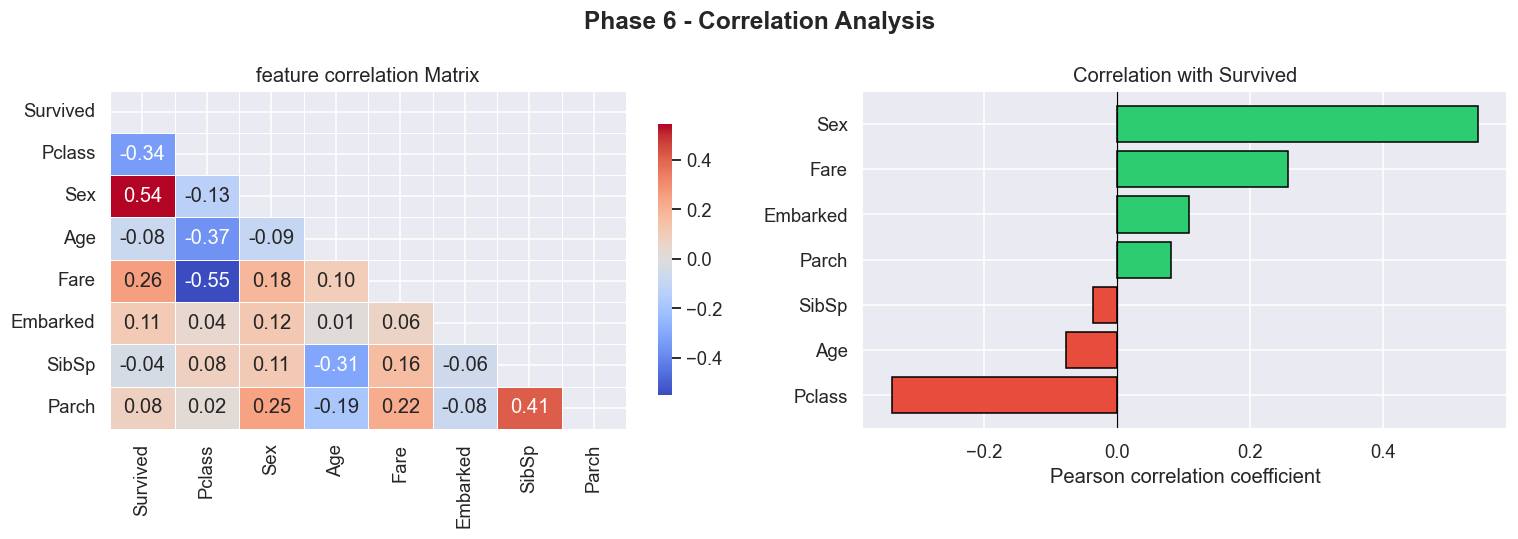

saved to tmp/phase6_correlation.png


In [14]:
df_enc = df.copy()
df_enc['Sex'] = df_enc['Sex'].map({'male':0,'female':1})
df_enc['Embarked'] = df_enc['Embarked'].map({'S':0,'C':1,'Q':2})

corr_cols = ['Survived','Pclass','Sex','Age','Fare','Embarked','SibSp','Parch']
corr = df_enc[corr_cols].corr()

print("Correlation with target variable (Survived):")
print(corr['Survived'].sort_values(ascending=False).sort_values(ascending=False).round(3))

fig,axes = plt.subplots(1,2,figsize=(14,5))
fig.suptitle("Phase 6 - Correlation Analysis", fontsize=16,fontweight='bold')

mask  = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask,annot=True, fmt=".2f", cmap='coolwarm', cbar_kws={"shrink": .8},linewidths=0.5, ax=axes[0])
axes[0].set_title("feature correlation Matrix")

#bar chart: correlation with target variable:
target_corr = corr['Survived'].drop('Survived').sort_values()
colors = [COLORS['survived'] if v > 0 else COLORS['died'] for v in target_corr.values]
axes[1].barh(target_corr.index, target_corr.values, color=colors, edgecolor='black')
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_title("Correlation with Survived")
axes[1].set_xlabel("Pearson correlation coefficient")

plt.tight_layout()
plt.savefig(PLOTS_DIR / "phase6_correlation.png",bbox_inches='tight')
plt.show()
print(f"saved to {PLOTS_DIR.name}/phase6_correlation.png")


## phase 7: multi variate :

Survival % by Pclass * sex:__--__--__--
Pclass     1     2     3
Sex                     
female  96.8  92.1  50.0
male    36.9  15.7  13.5


Age distribution by Pclass & Survival:__--__--__--


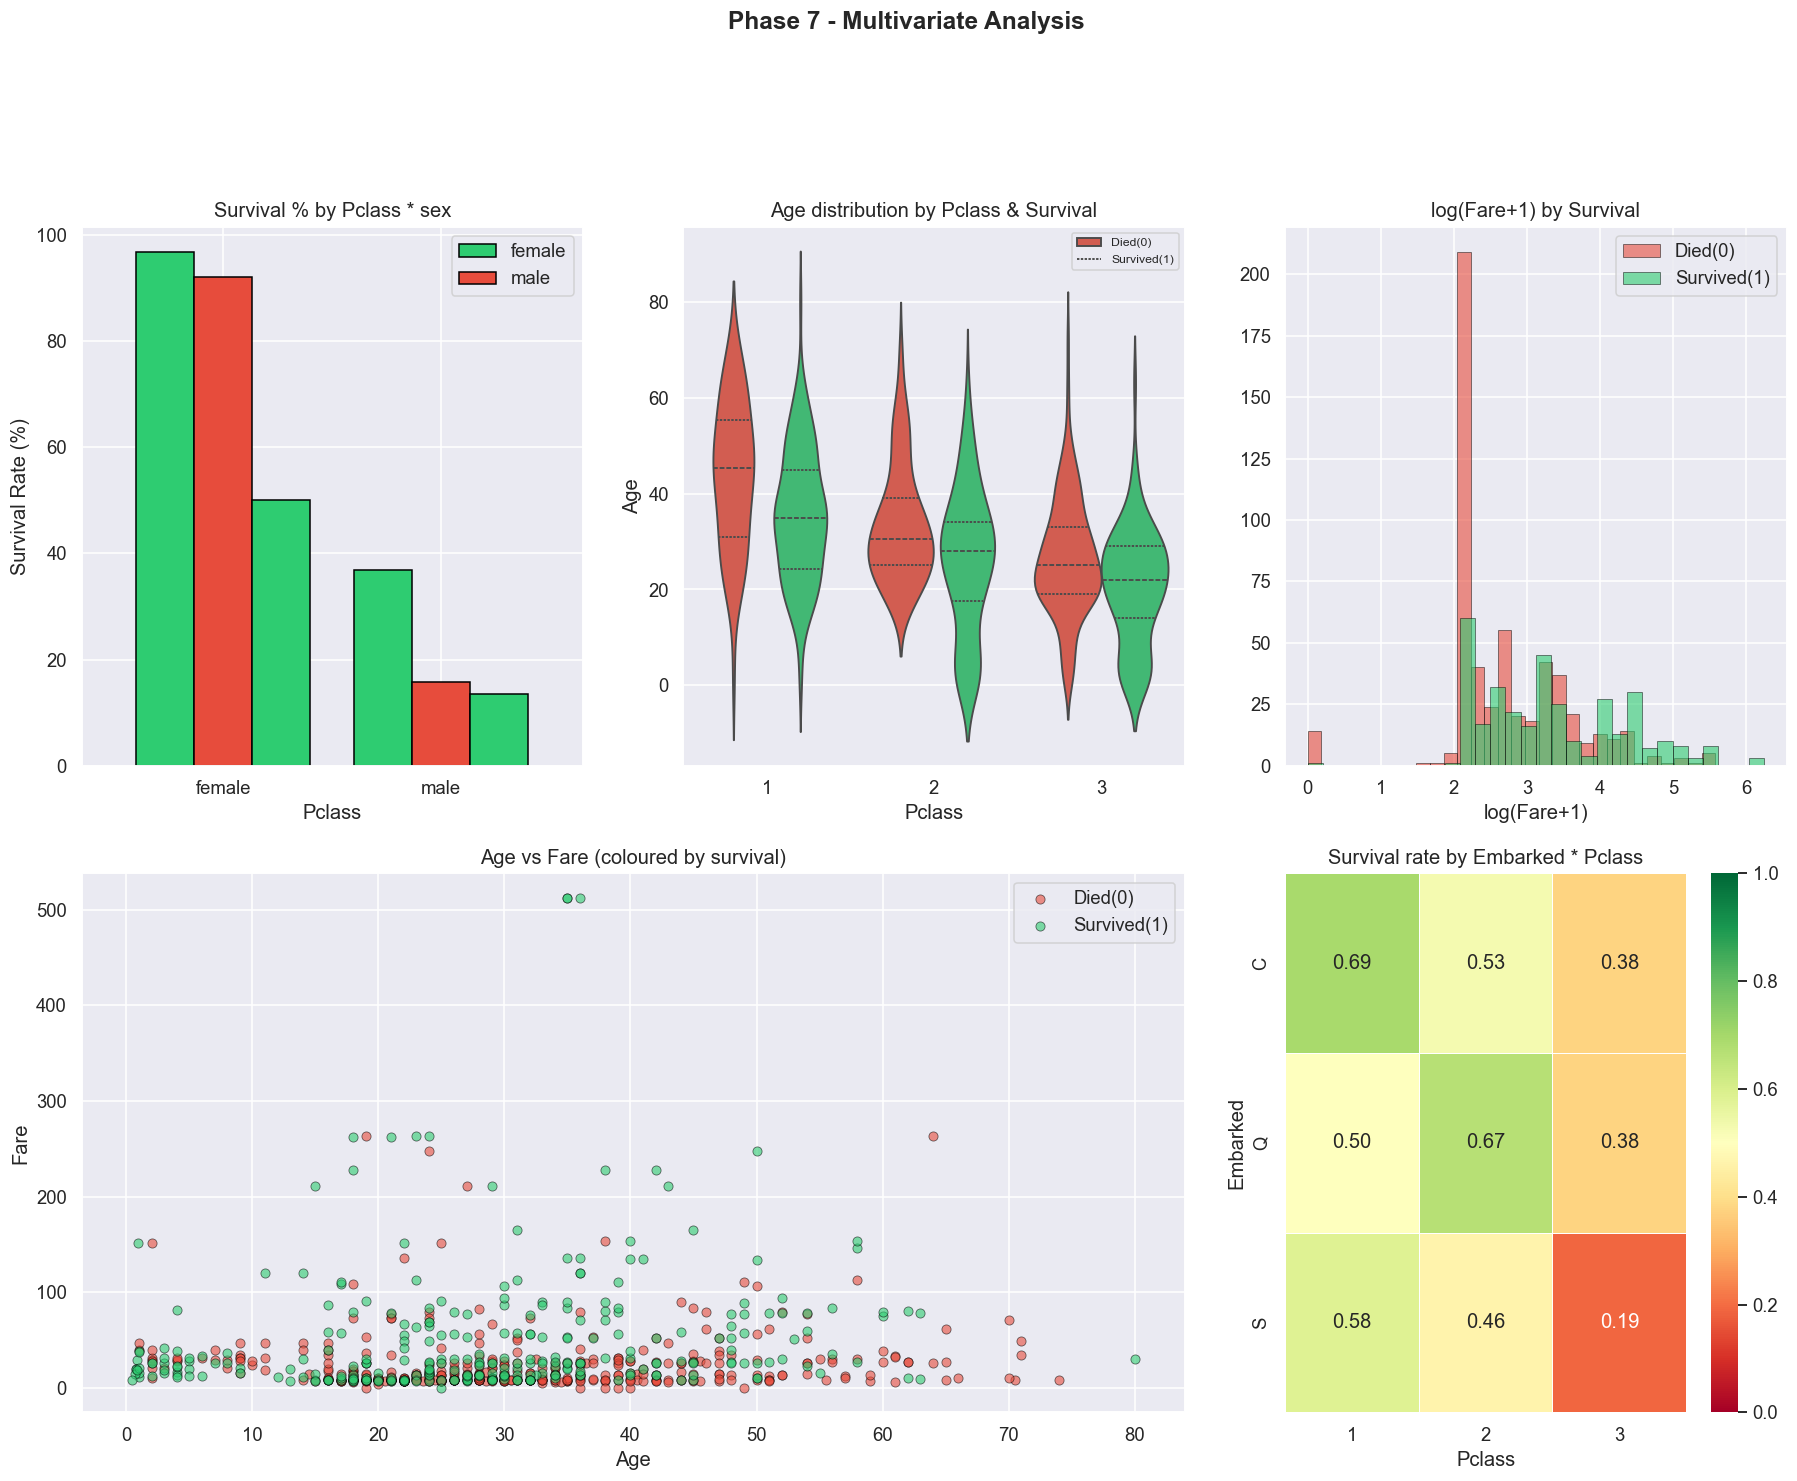

saved to tmp/phase7_multivariate.png


In [15]:
fig = plt.figure(figsize=(20,14))
fig.suptitle("Phase 7 - Multivariate Analysis", fontsize=16,fontweight='bold',y=1.02)
gs= gridspec.GridSpec(2,3, figure=fig)

#sex*Pclass*Survival(grouped bar chart):
ax1= fig.add_subplot(gs[0, 0])
cross = df.groupby(['Sex','Pclass'])['Survived'].mean().unstack()*100
cross.plot(kind='bar', ax=ax1, color=[COLORS['survived'], COLORS['died']],edgecolor='black',width=0.8)
ax1.set_title("Survival % by Pclass * sex")
ax1.set_ylabel("Survival Rate (%)")
ax1.set_xlabel("Pclass")
ax1.legend(['female','male'])
ax1.tick_params(axis='x',rotation=0)
print("Survival % by Pclass * sex:__--__--__--")
print(cross.round(1))

# age * pclass(violin plot):
ax2 = fig.add_subplot(gs[0, 1])
sns.violinplot(x='Pclass',y='Age',data=df,hue='Survived',inner='quart',palette=[COLORS['died'], COLORS['survived']],ax=ax2)
ax2.set_title("Age distribution by Pclass & Survival")
ax2.legend(["Died(0)","Survived(1)"],fontsize=8)
print("Age distribution by Pclass & Survival:__--__--__--")

# fare * survival(log scale):
ax3 = fig.add_subplot(gs[0, 2])
for label, grp in df.groupby('Survived'):
    ax3.hist(np.log1p(grp["Fare"]),bins=30,alpha=0.6,
             label=['Died(0)','Survived(1)'][label],
             color = [COLORS['died'], COLORS['survived']][label],
             edgecolor='black',linewidth=0.5)
    ax3.set_title("log(Fare+1) by Survival")
    ax3.set_xlabel("log(Fare+1)")
    ax3.legend()

# age * fare (scatter plot):( hue=survival,size=PClass)
ax4 = fig.add_subplot(gs[1, 0:2])
survived = df[df['Survived'] == 1]
died = df[df['Survived'] == 0]
ax4.scatter(died['Age'], died['Fare'], c=COLORS['died'], label='Died(0)', alpha=0.6, edgecolor='black', linewidth=0.5)
ax4.scatter(survived['Age'], survived['Fare'], c=COLORS['survived'], label='Survived(1)', alpha=0.6, edgecolor='black', linewidth=0.5)
ax4.set_title("Age vs Fare (coloured by survival)")
ax4.set_xlabel("Age")
ax4.set_ylabel("Fare")
ax4.legend()

# HEATmap - Pclass * Embarked * Survival rate:
ax5 = fig.add_subplot(gs[1, 2])
pivot = df.groupby(['Embarked','Pclass'])['Survived'].mean().unstack()
sns.heatmap(pivot, annot=True, fmt=".2f", cmap='RdYlGn', linewidths=0.5, ax=ax5,vmin=0, vmax=1)
ax5.set_title("Survival rate by Embarked * Pclass")

plt.tight_layout
plt.savefig(PLOTS_DIR / "phase7_multivariate.png",bbox_inches='tight')
plt.show()
print(f"saved to {PLOTS_DIR.name}/phase7_multivariate.png")


## Phase 8 - OUTLIER ANALYSIS

In [16]:
def outlier_summary(df,col):
    data = df[col].dropna()
    q1,q3 = data.quantile(0.25), data.quantile(0.75)
    IQR = q3 - q1
    lower = q1-1.5*IQR
    upper = q3+1.5*IQR
    iqr_out = ((data<lower)|(data>upper)).sum()
    z_out = (np.abs(stats.zscore(data)) > 3).sum()
    return {
        "IQR_outliers": iqr_out,
        "Z-score_outliers": z_out,
        "lower_bound": round(lower, 2),
        "upper_bound": round(upper, 2)
        }

for col in num_cols:
    r = outlier_summary(df, col)
    print(f"{col:8s} --> IQR outliers: {r['IQR_outliers']:>8}, Z-score outliers: {r['Z-score_outliers']}, lower bound: {r['lower_bound']}, upper bound: {r['upper_bound']}")

Age      --> IQR outliers:       11, Z-score outliers: 2, lower bound: -6.69, upper bound: 64.81
Fare     --> IQR outliers:      116, Z-score outliers: 20, lower bound: -26.72, upper bound: 65.63
SibSp    --> IQR outliers:       46, Z-score outliers: 30, lower bound: -1.5, upper bound: 2.5
Parch    --> IQR outliers:      213, Z-score outliers: 15, lower bound: 0.0, upper bound: 0.0


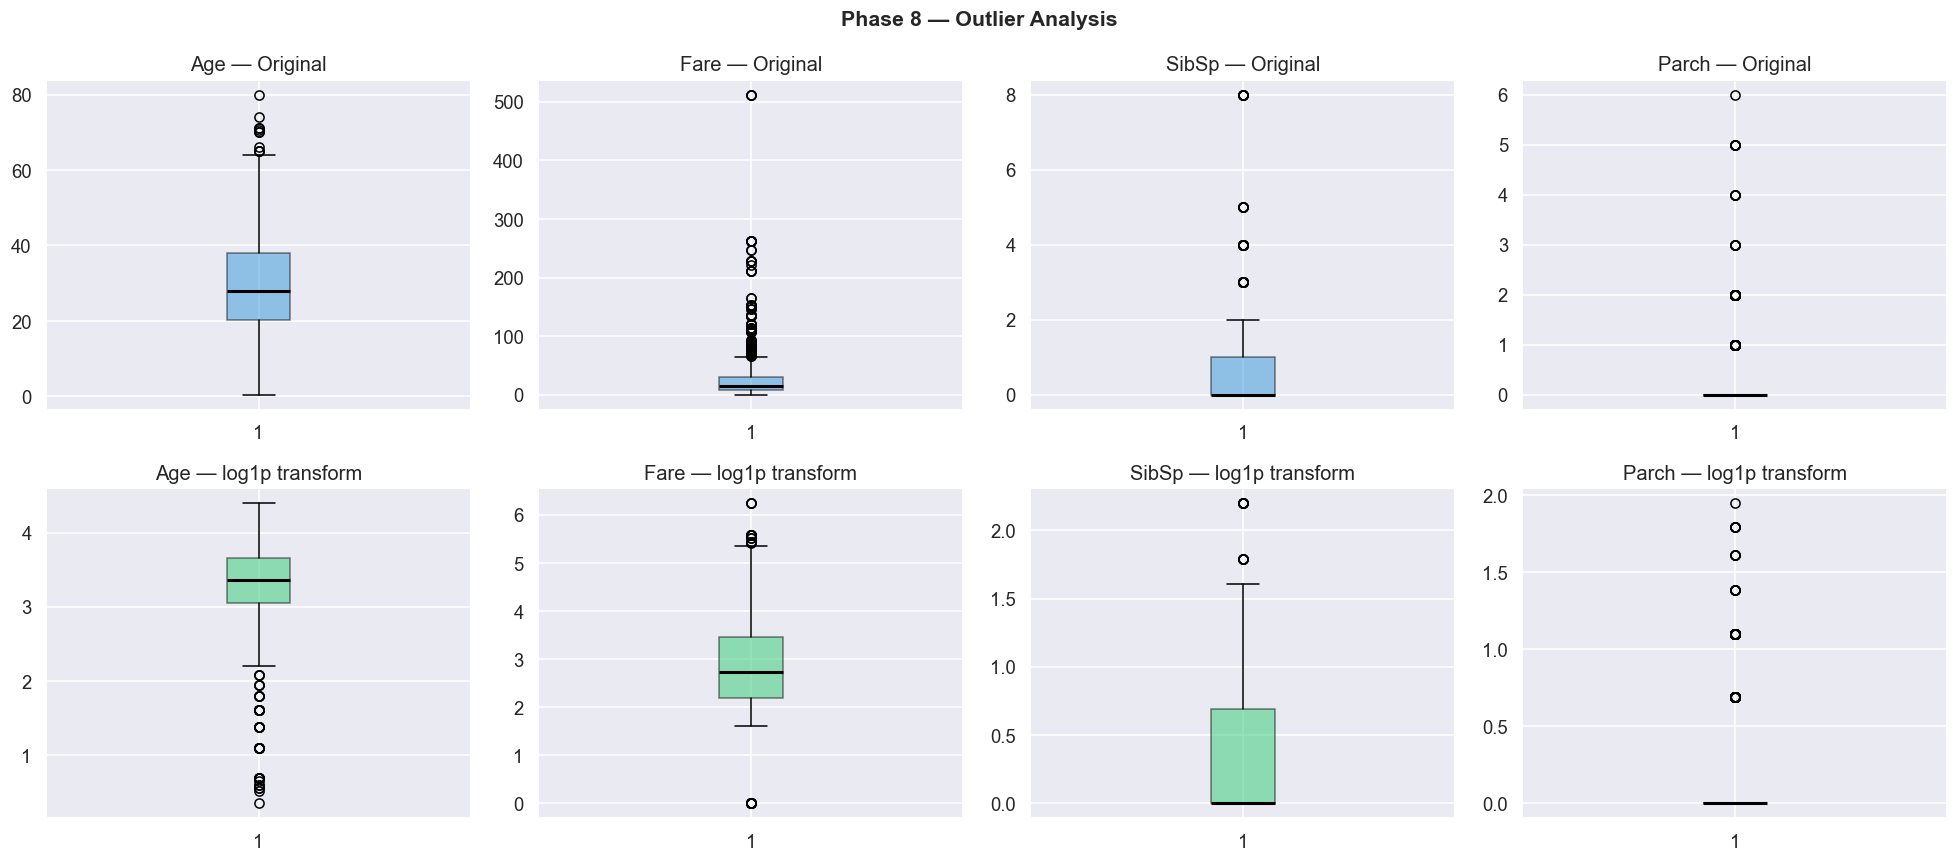

In [17]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
fig.suptitle("Phase 8 — Outlier Analysis", fontsize=14, fontweight="bold")
 
for i, col in enumerate(num_cols):
    data = df[col].dropna()
    # Before
    axes[0, i].boxplot(data, vert=True, patch_artist=True,
                       boxprops=dict(facecolor=COLORS["neutral"], alpha=0.5),
                       medianprops=dict(color="black", linewidth=2))
    axes[0, i].set_title(f"{col} — Original")
 
    # After log transform (for Fare & Age)
    axes[1, i].boxplot(np.log1p(data), vert=True, patch_artist=True,
                       boxprops=dict(facecolor=COLORS["survived"], alpha=0.5),
                       medianprops=dict(color="black", linewidth=2))
    axes[1, i].set_title(f"{col} — log1p transform")
 
plt.tight_layout()
plt.savefig(PLOTS_DIR / "phase8_outliers.png", bbox_inches="tight")
plt.show()

## Phase 9 - Feature engineering


── Title distribution ───────────────────────────────────
Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64

── Survival rate by Title ───────────────────────────────
Title
Mrs       0.794
Miss      0.703
Master    0.575
Rare      0.348
Mr        0.157
Name: Survived, dtype: float64

── survival rate by IsAlone ──────────────────────────────
IsAlone
0    0.506
1    0.304
Name: Survived, dtype: float64

── survival by Ageband distribution ─────────────────────────────────
Ageband
Child         0.580
Teenager      0.429
YoungAdult    0.383
Adult         0.400
Senior        0.227
Name: Survived, dtype: float64

── Survival by FareBand distribution ─────────────────────────────────
FareBand
Low          0.197
Mid          0.304
High         0.455
Very High    0.581
Name: Survived, dtype: float64

── Survival by HasCabin ─────────────────────────────────
HasCabin
0    0.300
1    0.667
Name: Survived, dtype: float64


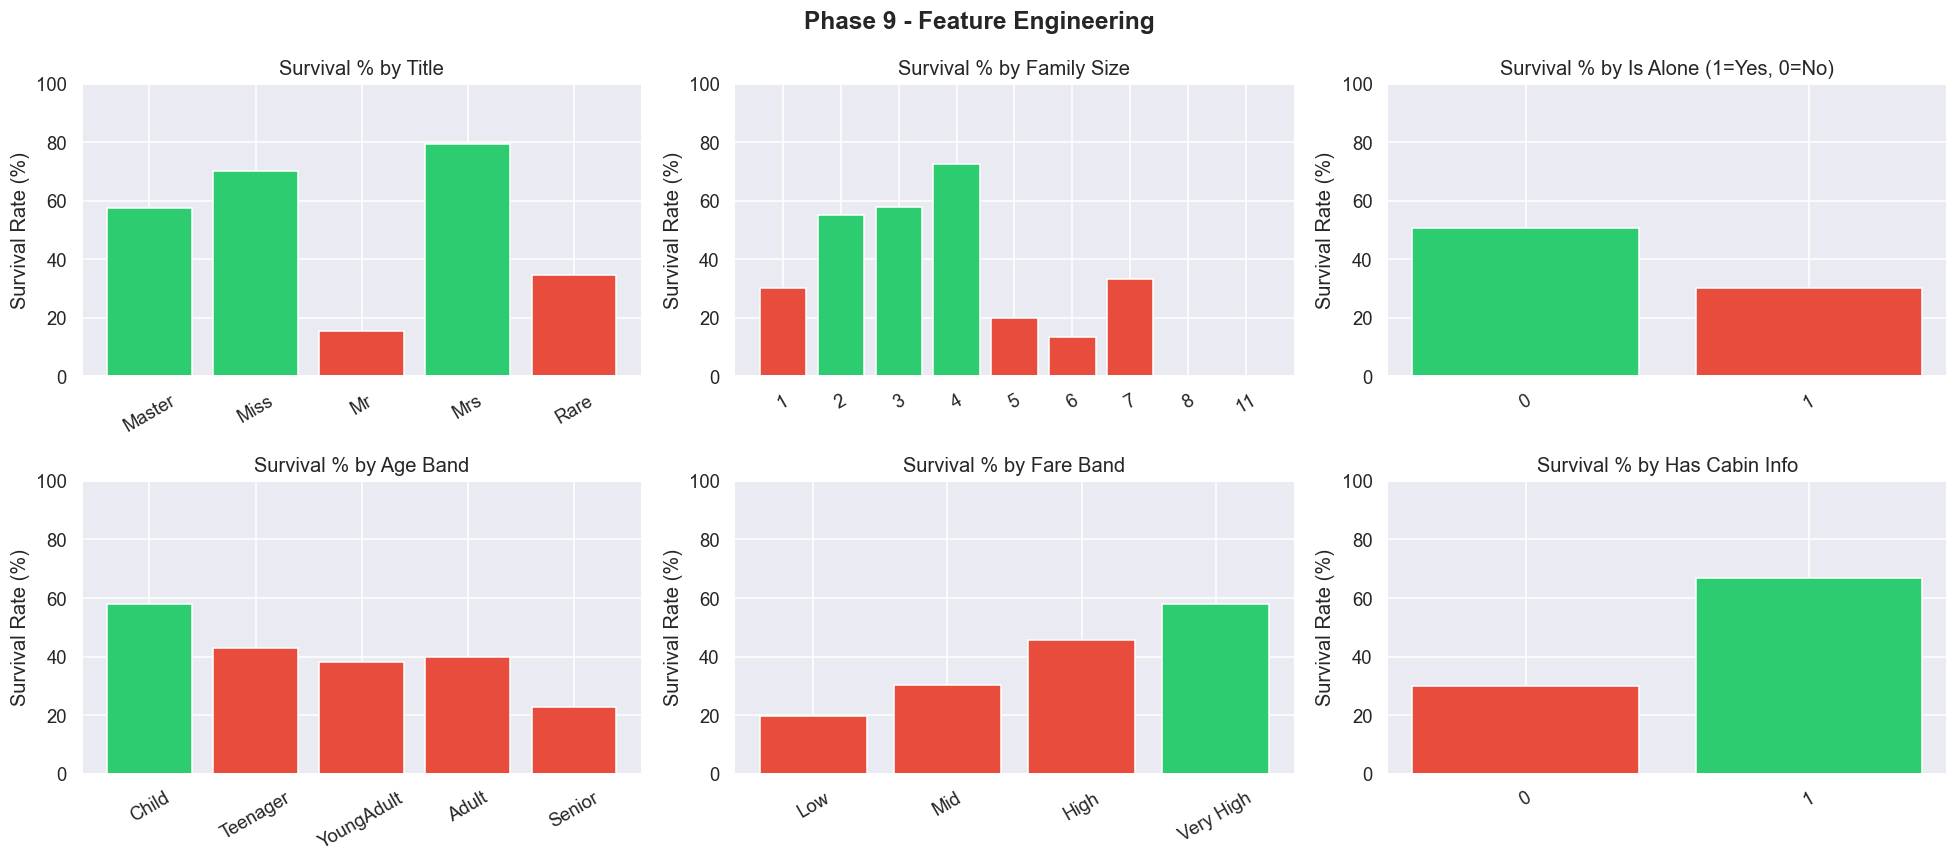

saved to tmp/phase9_feature-engineered.png


In [18]:
df_fe = df.copy()

#title from name:
df_fe['Title'] = df_fe['Name'].str.extract(r"([A-Za-z]+)\.",expand=False)
title_map = {
    "Mr": "Mr", "Miss": "Miss", "Mrs": "Mrs", "Master": "Master",
    "Dr": "Rare", "Rev": "Rare", "Col": "Rare", "Major": "Rare",
    "Mlle": "Miss", "Countess": "Rare", "Ms": "Miss", "Lady": "Rare",
    "Jonkheer": "Rare", "Don": "Rare", "Mme": "Mrs", "Capt": "Rare", "Sir": "Rare"
}
df_fe["Title"] = df_fe["Title"].map(title_map).fillna("Rare")
print("\n── Title distribution ───────────────────────────────────")
print(df_fe["Title"].value_counts())
print("\n── Survival rate by Title ───────────────────────────────")
print(df_fe.groupby("Title")["Survived"].mean().round(3).sort_values(ascending=False))

#familysize and is alone:
df_fe['FamilySize'] = df_fe['SibSp']+df_fe['Parch']+1
df_fe['IsAlone'] = (df_fe['FamilySize'] == 1).astype(int)
print("\n── survival rate by IsAlone ──────────────────────────────")
print(df_fe.groupby('IsAlone')['Survived'].mean().round(3))

#Age bins:
df_fe["Ageband"] = pd.cut(df_fe['Age'], bins=[0, 12, 18, 35, 60, np.inf], labels=["Child", "Teenager", "YoungAdult", "Adult", "Senior"])
print("\n── survival by Ageband distribution ─────────────────────────────────")
print(df_fe.groupby("Ageband",observed=True)['Survived'].mean().round(3))

#Fare bins:
df_fe['FareBand']=pd.qcut(df_fe['Fare'], q=4, labels=['Low', 'Mid', 'High', 'Very High'])
print("\n── Survival by FareBand distribution ─────────────────────────────────")
print(df_fe.groupby("FareBand",observed=True)['Survived'].mean().round(3))

#Has Cabin:
df_fe['HasCabin'] = df_fe['Cabin'].notnull().astype(int)
print("\n── Survival by HasCabin ─────────────────────────────────")
print(df_fe.groupby('HasCabin')['Survived'].mean().round(3))

#plot features:
fig,axes = plt.subplots(2,3,figsize=(18,8))
fig.suptitle("Phase 9 - Feature Engineering", fontsize=16,fontweight='bold')    

eng_features = [
    ("Title","Title"),
    ("FamilySize","Family Size"),
    ("IsAlone","Is Alone (1=Yes, 0=No)"),
    ("Ageband","Age Band"),
    ("FareBand","Fare Band"),
    ("HasCabin","Has Cabin Info")
]

for idx,(feat,label) in enumerate(eng_features):
    ax = axes[idx // 3][idx % 3]
    sr = df_fe.groupby(feat, observed=True)["Survived"].mean() * 100
    colors = [COLORS["survived"] if v >= 50 else COLORS["died"] for v in sr.values]
    ax.bar(sr.index.astype(str), sr.values, color=colors, edgecolor="white")
    ax.set_title(f"Survival % by {label}")
    ax.set_ylabel("Survival Rate (%)")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=30)
 
plt.tight_layout()
plt.savefig(PLOTS_DIR / "phase9_feature-engineered.png", bbox_inches="tight")
plt.show()
print(f"saved to {PLOTS_DIR.name}/phase9_feature-engineered.png")